# California Housing Regression — Datheon Task 2

Compare ordinary least squares (OLS), Ridge, and Lasso when predicting
`median_house_value` from the supplied `housing.csv`.
Each row describes a California census block group, not an individual house.
This is a historical benchmark based on the 1990 census.

All models use the same 80/20 split and engineered features. Preprocessing
is learned within each training fold. Alpha and the preferred model are
selected using training cross-validation before the test results are viewed.
RMSE and MAE are reported in the CSV's house-value dollars; R² is unitless.


## 1. Imports and output folders

Run the notebook from this project folder, with `housing.csv` beside it.
Figures and result tables are saved into relative subfolders.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

Path("figures").mkdir(exist_ok=True)
Path("results").mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")


## 2. Load and check the data


In [2]:
housing = pd.read_csv("housing.csv")
print("Rows and columns:", housing.shape)
print(housing.head().to_string(index=False))
housing.info()

print("\nMissing values:")
print(housing.isna().sum().to_string())
print("\nRepeated rows:", housing.duplicated().sum())
print("\nOcean proximity:")
print(housing["ocean_proximity"].value_counts().to_string())
print("\nNumeric summary:")
print(housing.describe().round(2).to_string())


Rows and columns: (20640, 10)
 longitude  latitude  housing_median_age  total_rooms  total_bedrooms  population  households  median_income  median_house_value ocean_proximity
   -122.23     37.88                41.0        880.0           129.0       322.0       126.0         8.3252            452600.0        NEAR BAY
   -122.22     37.86                21.0       7099.0          1106.0      2401.0      1138.0         8.3014            358500.0        NEAR BAY
   -122.24     37.85                52.0       1467.0           190.0       496.0       177.0         7.2574            352100.0        NEAR BAY
   -122.25     37.85                52.0       1274.0           235.0       558.0       219.0         5.6431            341300.0        NEAR BAY
   -122.25     37.85                52.0       1627.0           280.0       565.0       259.0         3.8462            342200.0        NEAR BAY
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 c

In [3]:
if housing["median_house_value"].isna().any():
    raise ValueError("The target contains missing values.")
if (housing[["households", "total_rooms"]] <= 0).any().any():
    raise ValueError("Ratio denominators must be positive.")

capped_count = housing["median_house_value"].eq(500001).sum()
print("Rows recorded at $500,001:", capped_count)
print("Percentage at this limit:", round(100 * capped_count / len(housing), 2))
print("Missing bedroom values:", housing["total_bedrooms"].isna().sum())


Rows recorded at $500,001: 965
Percentage at this limit: 4.68
Missing bedroom values: 207


The supplied file has 207 missing `total_bedrooms` entries, no repeated
complete rows, and five ocean categories. Missing bedrooms will be imputed
using training medians. All 20,640 rows are retained. Values recorded at
$500,001 and unusually large measurements are kept; the target's upper
limit affects interpretation of high-value predictions.


## 3. Reserve the test set

Use 16,512 training rows and 4,128 test rows. The fixed random split
estimates performance on similar sampled areas; it does not test transfer
to a later year or a geographically separate region.


In [4]:
X = housing.drop(columns="median_house_value")
y = housing["median_house_value"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Missing bedrooms in training:", X_train["total_bedrooms"].isna().sum())
print("Missing bedrooms in test:", X_test["total_bedrooms"].isna().sum())


Training rows: 16512
Test rows: 4128
Missing bedrooms in training: 0
Missing bedrooms in test: 207


## 4. Explore the training data


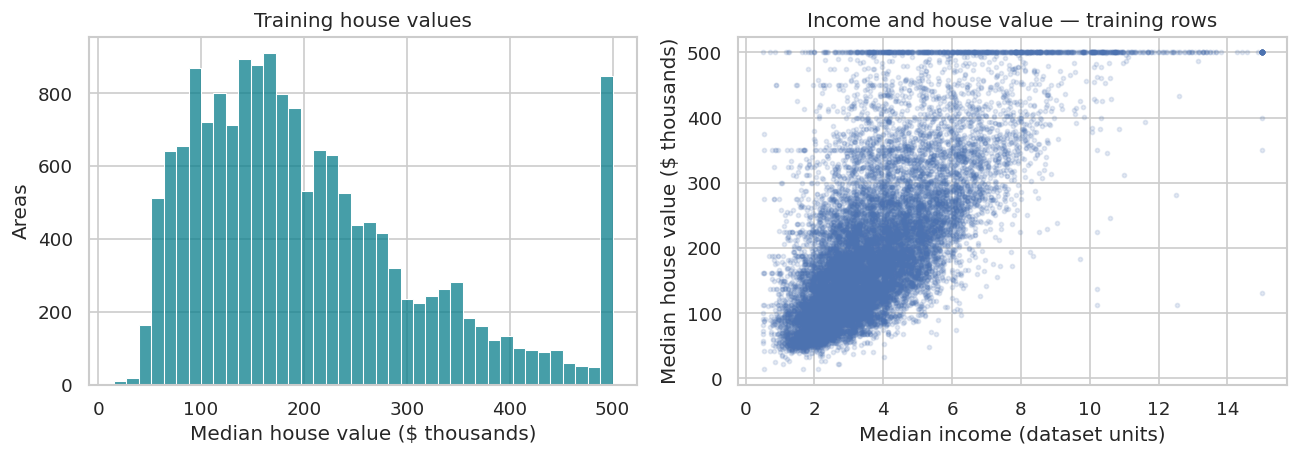

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(y_train / 1000, bins=40, ax=axes[0], color="#087E8B")
axes[0].set_title("Training house values")
axes[0].set_xlabel("Median house value ($ thousands)")
axes[0].set_ylabel("Areas")
axes[1].scatter(X_train["median_income"], y_train / 1000, s=6, alpha=0.15)
axes[1].set_title("Income and house value — training rows")
axes[1].set_xlabel("Median income (dataset units)")
axes[1].set_ylabel("Median house value ($ thousands)")
plt.tight_layout()
plt.savefig("figures/training_distributions.png", dpi=150)
plt.show()


                total_rooms  total_bedrooms  households
total_rooms            1.00            0.93        0.92
total_bedrooms         0.93            1.00        0.98
households             0.92            0.98        1.00


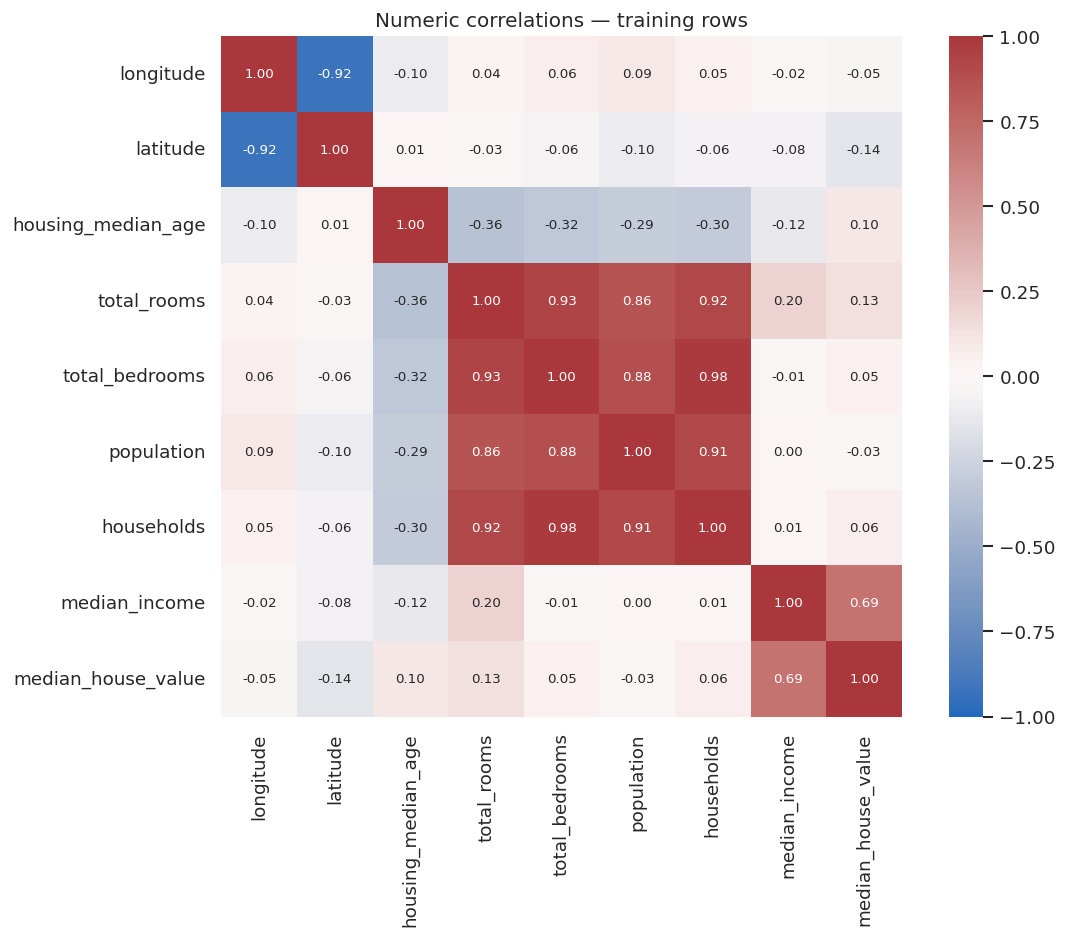

In [6]:
training_data = X_train.copy()
training_data["median_house_value"] = y_train
correlations = training_data.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(correlations, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True, annot_kws={"size": 8})
plt.title("Numeric correlations — training rows")
plt.tight_layout()
plt.savefig("figures/training_correlations.png", dpi=150)
plt.show()
print(correlations.loc[["total_rooms", "total_bedrooms", "households"],
                       ["total_rooms", "total_bedrooms", "households"]].round(3))


Rooms, bedrooms, population, and households contain overlapping area-size
information. Ridge and Lasso address coefficient instability through
penalties. One ocean indicator is dropped below to avoid an exact linear
dependency with the intercept. No predictor is selected using test scores.


## 5. Create ratios and an interaction

Add rooms per household, bedrooms per room, population per household, and
an income × rooms-per-household interaction. These use values within each
row and learn no statistics from other rows. Missing bedrooms also create
a missing bedroom ratio; both columns are imputed later within the pipeline.


In [7]:
def add_features(data):
    """Return a copy with three ratios and one interaction."""
    features = data.copy()
    features["rooms_per_household"] = features["total_rooms"] / features["households"]
    features["bedrooms_per_room"] = features["total_bedrooms"] / features["total_rooms"]
    features["population_per_household"] = features["population"] / features["households"]
    features["income_x_rooms"] = features["median_income"] * features["rooms_per_household"]
    return features

X_train_features = add_features(X_train)
X_test_features = add_features(X_test)
numeric_columns = X_train_features.select_dtypes(include="number").columns.tolist()
categorical_columns = ["ocean_proximity"]
print(X_train_features[["rooms_per_household", "bedrooms_per_room",
                        "population_per_household", "income_x_rooms"]].head().round(3))


       rooms_per_household  ...  income_x_rooms
14196                5.018  ...          16.356
8267                 4.474  ...          17.055
17445                5.646  ...          23.466
14265                4.003  ...           7.775
2271                 6.268  ...          22.279

[5 rows x 4 columns]


## 6. Build preprocessing into each model


In [8]:
def build_pipeline(model):
    """Make fresh preprocessing steps followed by a regression model."""
    numeric_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    preprocessing = ColumnTransformer([
        ("numeric", numeric_steps, numeric_columns),
        ("category", OneHotEncoder(drop="first", handle_unknown="ignore",
                                   sparse_output=False), categorical_columns)
    ], verbose_feature_names_out=False)
    return Pipeline([("preprocess", preprocessing), ("model", model)])

cv = KFold(n_splits=5, shuffle=True, random_state=42)


The pipelines keep medians, category vocabularies, and scaling statistics
inside each cross-validation fit. Numeric values are standardised;
category indicators remain 0/1. Alpha values are specified before scoring.


## 7. Fit OLS and tune Ridge and Lasso


In [9]:
ols_model = build_pipeline(LinearRegression())
ols_cv_rmse = -cross_val_score(
    ols_model, X_train_features, y_train,
    scoring="neg_root_mean_squared_error", cv=cv
)
ols_model.fit(X_train_features, y_train)
print("OLS mean CV RMSE:", round(ols_cv_rmse.mean(), 2))


OLS mean CV RMSE: 67779.46


In [10]:
ridge_search = GridSearchCV(
    build_pipeline(Ridge()),
    {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1, error_score="raise"
)
ridge_search.fit(X_train_features, y_train)
ridge_model = ridge_search.best_estimator_
print("Ridge best alpha:", ridge_search.best_params_["model__alpha"])
print("Ridge mean CV RMSE:", round(-ridge_search.best_score_, 2))


Ridge best alpha: 10
Ridge mean CV RMSE: 67766.95


In [11]:
lasso_search = GridSearchCV(
    build_pipeline(Lasso(max_iter=20000, tol=0.0001)),
    {"model__alpha": [1, 10, 100, 1000, 10000]},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1, error_score="raise"
)
lasso_search.fit(X_train_features, y_train)
lasso_model = lasso_search.best_estimator_
print("Lasso best alpha:", lasso_search.best_params_["model__alpha"])
print("Lasso mean CV RMSE:", round(-lasso_search.best_score_, 2))
print("Iterations in the refitted Lasso:", lasso_model.named_steps["model"].n_iter_)


Lasso best alpha: 100
Lasso mean CV RMSE: 67768.23
Iterations in the refitted Lasso: 159


In [12]:
ridge_results = pd.DataFrame(ridge_search.cv_results_)
lasso_results = pd.DataFrame(lasso_search.cv_results_)
cv_comparison = pd.DataFrame({
    "Model": ["OLS", "Ridge", "Lasso"],
    "CV_RMSE": [ols_cv_rmse.mean(), -ridge_search.best_score_, -lasso_search.best_score_],
    "Fold_SD": [ols_cv_rmse.std(),
                ridge_results.loc[ridge_search.best_index_, "std_test_score"],
                lasso_results.loc[lasso_search.best_index_, "std_test_score"]]
})
selected_name = cv_comparison.sort_values("CV_RMSE").iloc[0]["Model"]
print(cv_comparison.round(2).to_string(index=False))
print("Selected using training CV:", selected_name)
cv_comparison.to_csv("results/cv_comparison.csv", index=False)


Model  CV_RMSE  Fold_SD
  OLS 67779.46  1386.29
Ridge 67766.95  1371.89
Lasso 67768.23  1354.82
Selected using training CV: Ridge


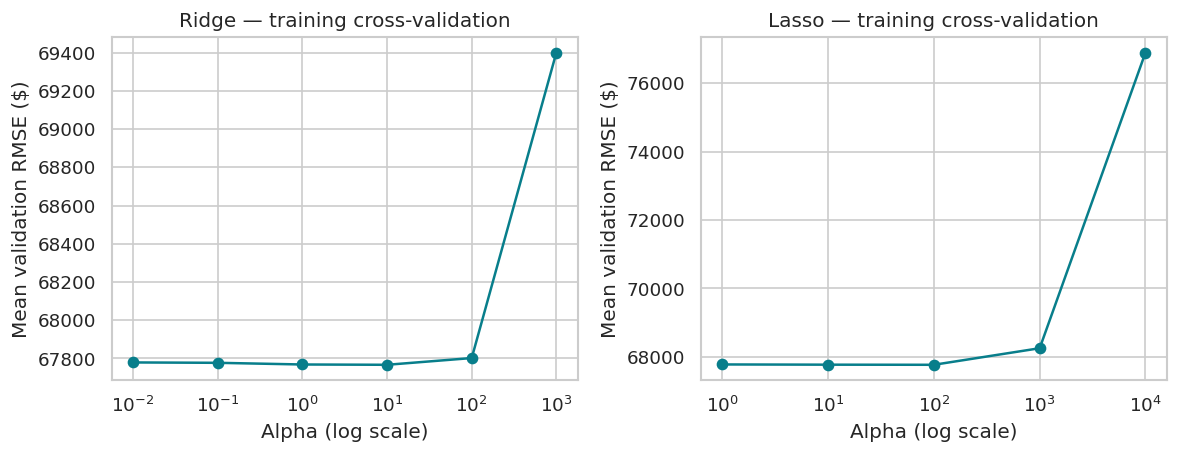

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, results, name in zip(axes, [ridge_results, lasso_results], ["Ridge", "Lasso"]):
    alpha_values = results["param_model__alpha"].astype(float)
    ax.plot(alpha_values, -results["mean_test_score"], marker="o", color="#087E8B")
    ax.set_xscale("log")
    ax.set_title(name + " — training cross-validation")
    ax.set_xlabel("Alpha (log scale)")
    ax.set_ylabel("Mean validation RMSE ($)")
plt.tight_layout()
plt.savefig("figures/alpha_validation.png", dpi=150)
plt.show()


## 8. Evaluate once on the reserved test set


In [14]:
model_names = ["OLS", "Ridge", "Lasso"]
test_predictions = pd.DataFrame({"Actual": y_test})
test_predictions["OLS"] = ols_model.predict(X_test_features)
test_predictions["Ridge"] = ridge_model.predict(X_test_features)
test_predictions["Lasso"] = lasso_model.predict(X_test_features)

metric_rows = []
for name in model_names:
    prediction = test_predictions[name]
    metric_rows.append({
        "Model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, prediction)),
        "MAE": mean_absolute_error(y_test, prediction),
        "R2": r2_score(y_test, prediction)
    })
model_comparison = pd.DataFrame(metric_rows)
print(model_comparison.round(4).to_string(index=False))
model_comparison.to_csv("results/model_comparison.csv", index=False)
test_predictions.to_csv("results/test_predictions.csv", index_label="original_row_index")


Model       RMSE        MAE     R2
  OLS 68917.3167 49709.5395 0.6375
Ridge 68968.4864 49727.6802 0.6370
Lasso 69003.1250 49691.6919 0.6366


In [15]:
baseline_predictions = np.full(len(y_test), y_train.mean())
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_predictions))
print("Training-mean baseline test RMSE: $" + f"{baseline_rmse:,.2f}")


Training-mean baseline test RMSE: $114,485.64


## 9. Inspect prediction errors


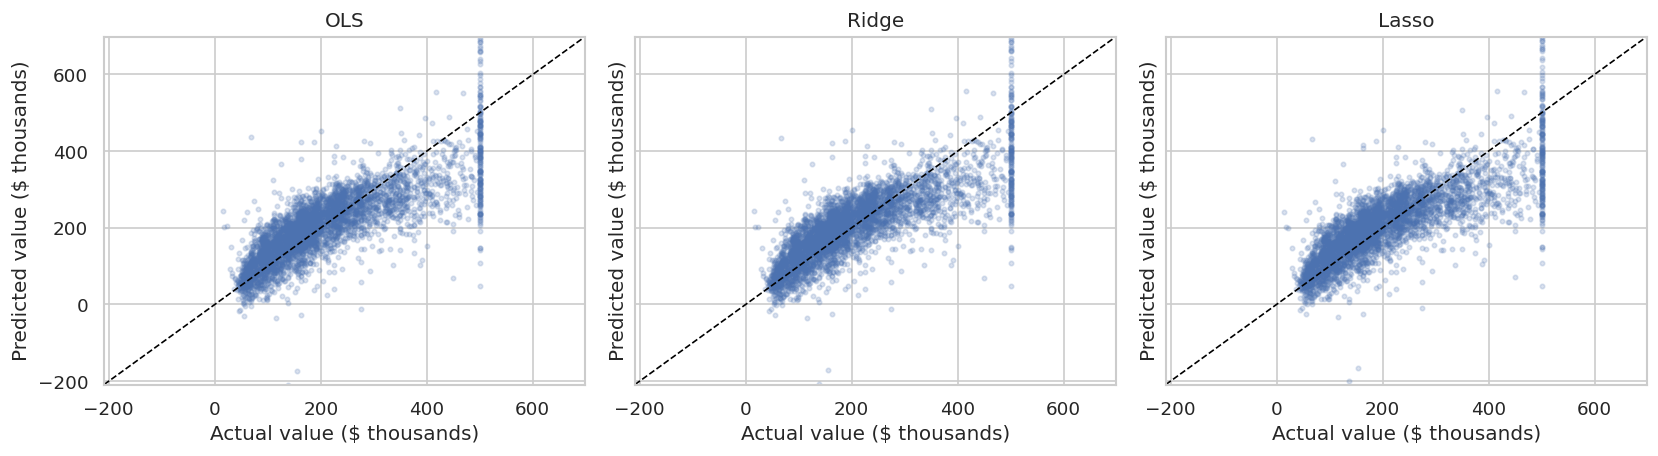

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
plot_min = min(y_test.min(), test_predictions[model_names].min().min()) / 1000
plot_max = max(y_test.max(), test_predictions[model_names].max().max()) / 1000
for ax, name in zip(axes, model_names):
    ax.scatter(y_test / 1000, test_predictions[name] / 1000, s=7, alpha=0.2)
    ax.plot([plot_min, plot_max], [plot_min, plot_max], "--", color="black", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Actual value ($ thousands)")
    ax.set_ylabel("Predicted value ($ thousands)")
    ax.set_xlim(plot_min, plot_max)
    ax.set_ylim(plot_min, plot_max)
plt.tight_layout()
plt.savefig("figures/predicted_vs_actual.png", dpi=150)
plt.show()


In [17]:
residuals = pd.DataFrame(index=y_test.index)
for name in model_names:
    residuals[name] = y_test - test_predictions[name]
print(residuals.describe().round(2).to_string())
residuals.to_csv("results/test_residuals.csv", index_label="original_row_index")


             OLS      Ridge      Lasso
count    4128.00    4128.00    4128.00
mean      899.89     900.42     883.02
std     68919.79   68970.96   69005.83
min   -369096.38 -368036.67 -364072.42
25%    -41790.94  -41914.74  -41900.10
50%     -8577.71   -8577.81   -8705.33
75%     30294.95   30188.12   30114.44
max    451677.14  452115.71  452980.65


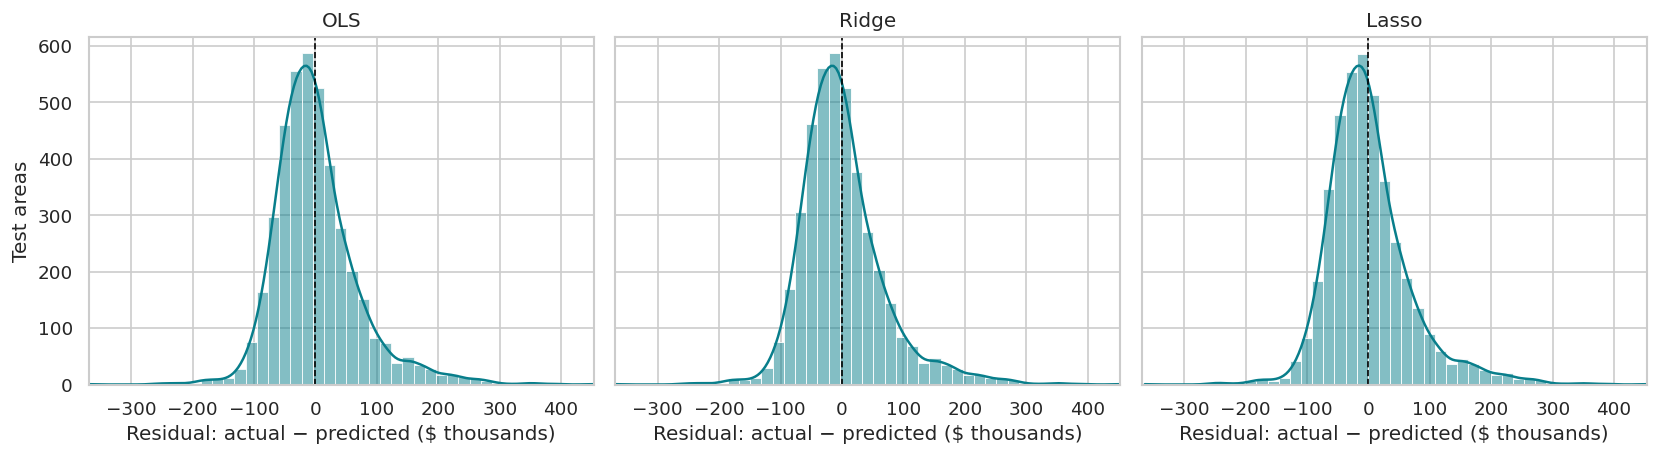

In [18]:
residual_min = residuals.min().min() / 1000
residual_max = residuals.max().max() / 1000
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, name in zip(axes, model_names):
    sns.histplot(residuals[name] / 1000, bins=45, kde=True,
                 color="#087E8B", ax=ax)
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Residual: actual − predicted ($ thousands)")
    ax.set_ylabel("Test areas")
    ax.set_xlim(residual_min, residual_max)
plt.tight_layout()
plt.savefig("figures/residual_distributions.png", dpi=150)
plt.show()


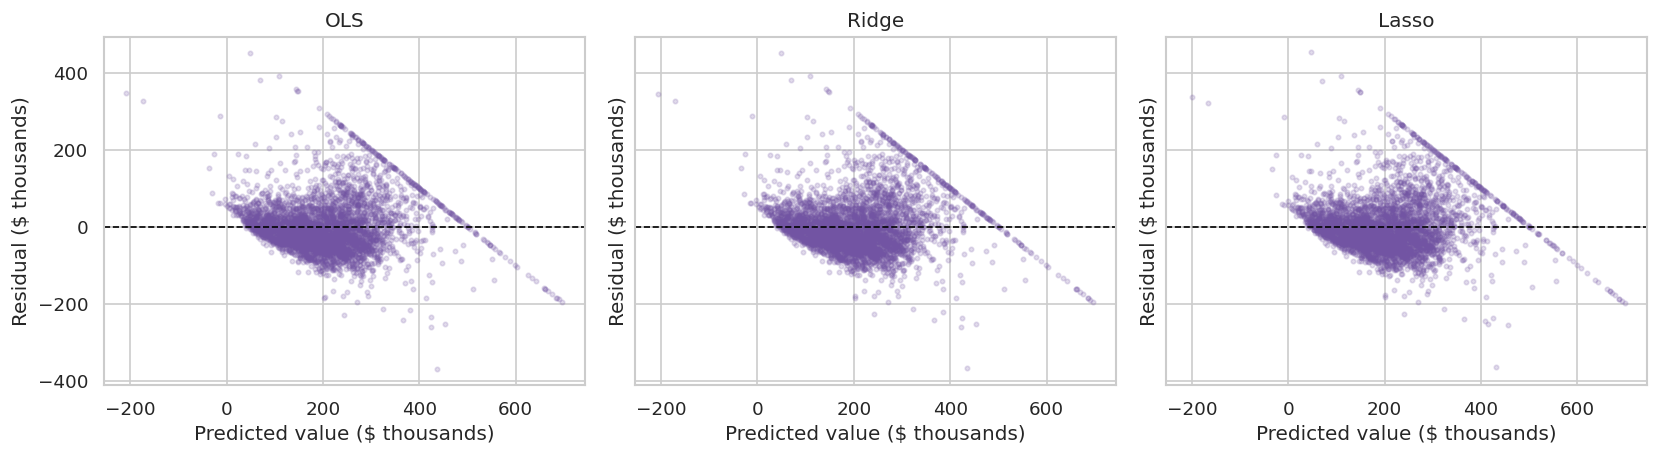

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, name in zip(axes, model_names):
    ax.scatter(test_predictions[name] / 1000, residuals[name] / 1000,
               s=7, alpha=0.2, color="#7254A3")
    ax.axhline(0, color="black", linestyle="--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("Predicted value ($ thousands)")
    ax.set_ylabel("Residual ($ thousands)")
plt.tight_layout()
plt.savefig("figures/residuals_vs_fitted.png", dpi=150)
plt.show()


## 10. Compare coefficients


In [20]:
feature_names = ols_model.named_steps["preprocess"].get_feature_names_out()
coefficients = pd.DataFrame({
    "Feature": feature_names,
    "OLS": ols_model.named_steps["model"].coef_,
    "Ridge": ridge_model.named_steps["model"].coef_,
    "Lasso": lasso_model.named_steps["model"].coef_
})
print(coefficients.round(2).to_string(index=False))
lasso_zero_count = np.isclose(coefficients["Lasso"], 0, atol=1e-8).sum()
print("Lasso zero coefficients:", lasso_zero_count, "of", len(coefficients))
coefficients.to_csv("results/coefficients.csv", index=False)


                   Feature       OLS     Ridge     Lasso
                 longitude -55498.43 -54745.18 -53178.18
                  latitude -55796.58 -55023.77 -53649.94
        housing_median_age  14260.78  14282.83  14098.38
               total_rooms   7124.01   6997.50   5906.00
            total_bedrooms   6998.97   7765.16   8039.10
                population -45386.67 -45094.49 -44157.72
                households  36348.72  35438.79  35239.84
             median_income  92154.73  91441.81  89303.48
       rooms_per_household  14106.87  13648.41  12340.45
         bedrooms_per_room  18206.98  18048.19  17521.07
  population_per_household    473.72    453.64    294.75
            income_x_rooms -16328.86 -15473.90 -12720.45
    ocean_proximity_INLAND -33944.76 -34438.30 -34909.83
    ocean_proximity_ISLAND 130435.70  37297.22      0.00
  ocean_proximity_NEAR BAY  -5277.50  -5110.59  -3246.64
ocean_proximity_NEAR OCEAN   3451.56   3553.32   3280.00
Lasso zero coefficients: 1 of 1

In [21]:
tuning_tables = []
for results, name in zip([ridge_results, lasso_results], ["Ridge", "Lasso"]):
    table = pd.DataFrame({
        "Model": name,
        "Alpha": results["param_model__alpha"].astype(float),
        "Mean_CV_RMSE": -results["mean_test_score"],
        "Fold_SD": results["std_test_score"]
    })
    tuning_tables.append(table)
tuning_results = pd.concat(tuning_tables, ignore_index=True)
print(tuning_results.round(2).to_string(index=False))
tuning_results.to_csv("results/alpha_search.csv", index=False)


Model    Alpha  Mean_CV_RMSE  Fold_SD
Ridge     0.01      67779.22  1386.13
Ridge     0.10      67777.29  1384.82
Ridge     1.00      67768.50  1378.90
Ridge    10.00      67766.95  1371.89
Ridge   100.00      67802.24  1288.56
Ridge  1000.00      69401.14  1219.56
Lasso     1.00      67778.16  1385.24
Lasso    10.00      67771.58  1379.62
Lasso   100.00      67768.23  1354.82
Lasso  1000.00      68252.79  1259.05
Lasso 10000.00      76899.87  1336.59


## 11. Check implausible estimates

Linear regression does not constrain predictions to positive values or to
the recorded target range. Count negative estimates and retain them in
the reported metrics rather than silently clipping prediction errors.


In [22]:
negative_predictions = test_predictions[model_names].lt(0).sum()
print("Negative test predictions:")
print(negative_predictions.to_string())


Negative test predictions:
OLS      10
Ridge    10
Lasso     9


## 12. Findings and limitations

- Ridge with alpha 10 was selected using training CV.
  Its test RMSE is $68,968.49, MAE is
  $49,727.68, and R² is 0.6370.
- OLS has the lowest test RMSE ($68,917.32);
  Lasso has the lowest test MAE ($49,691.69).
  The three models perform similarly. Small score differences do not
  establish a reliable winner, and no test-based retuning was performed.
- The training-mean baseline has test RMSE $114,485.64.
  Ridge reduces this error by 39.76% on this particular split.
- Lasso's selected alpha is 100; it sets one of
  16 coefficients to zero, for the rare ISLAND category. This is not
  evidence that island location has no association with value.
- The value cap produces a visible band at $500,001. Residuals have
  substantial tails and changing spread. Predictions can be negative
  or exceed the recorded maximum; they are not suitable as individual
  property appraisals.
- The data describe areas in 1990. The split may place nearby areas in
  both samples. These results do not establish performance on current
  prices, individual houses, or unseen regions. Spatial validation and
  a better treatment of capped outcomes would be useful future work.


## Sources

The supplied CSV was analysed directly, without substituting a built-in
dataset. Source background and the dataset listing are documented in
`ATTRIBUTION.md`.

- [Dataset maintainer's documentation](https://github.com/ageron/data/blob/main/housing/README.md)
- [California Housing Prices dataset listing](https://www.kaggle.com/datasets/camnugent/california-housing-prices)
- [Pipelines and leakage](https://scikit-learn.org/1.8/common_pitfalls.html#data-leakage)
- [GridSearchCV](https://scikit-learn.org/1.8/modules/generated/sklearn.model_selection.GridSearchCV.html)
- [Linear regression, Ridge, and Lasso](https://scikit-learn.org/1.8/modules/linear_model.html)
